# Step 1 — baseline and main model, leave-one-cycle-out (LOCO)

Each of the 7 cycles is the test set once; the other 6 train the model. Hyper-parameters are chosen by an inner LOCO over the 6 training cycles (mean inner AUROC); preprocessing is fit on training rows only. Outcome: depression = PHQ-9 ≥ 10. The code is in `nhanes/loco.py` (`run_loco`), shared with steps 2–7.

**Models** (both use class weights for the 8.9% prevalence)

- **logreg:** elastic-net logistic regression. Categorical features one-hot (−1 and missing are their own levels); numeric features: −1 → "not applicable" indicator + NaN, median imputation, standardised. Grid C ∈ {0.01, 0.1, 1} × l1_ratio ∈ {0, 0.5, 1}.
- **xgboost:** gradient-boosted trees on the table as it is (NaN and −1 handled by the trees); max_depth ∈ {3, 5} × min_child_weight ∈ {1, 10}, number of trees by early stopping in the inner folds.

**Metrics** (primary: AUROC, the mean over the 7 test cycles, each cycle weighted equally): per test cycle AUROC, survey-weighted AUROC (WTMEC2YR), AUPRC, Brier score; plus the AUROC of all out-of-cycle predictions pooled.

**Output:** `$NHANES_WORK/modeling/step1/` `predictions.csv.gz`, `metrics.csv`, `chosen_params.json`, `report.txt`

`RUN = True` retrains (about 2 hours on 4 threads; elastic net ≈ 14 min per fold); `QUICK = True` with it runs one outer fold with the smallest grids. `RUN = False` only shows the saved results.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS, WORK  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step1
QUICK = False  # with RUN: one outer fold, smallest grids
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step1"

## Run

In [2]:
if RUN:
    from nhanes.loco import FEAT, run_loco
    data = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    run_loco(data, dic, OUT, QUICK)

## Results

In [3]:
print((OUT / "report.txt").read_text())

leave-one-cycle-out, outcome PHQ-9 >= 10

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.874  0.011          0.877  0.018  0.481  0.036  0.137  0.007
xgboost  0.871  0.010          0.875  0.016  0.481  0.032  0.129  0.005

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.872
xgboost    0.870

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier    n  prevalence  minutes
 logreg    2005-06  0.894           0.903  0.504  0.126 3975       0.062     14.4
xgboost    2005-06  0.888           0.897  0.504  0.122 3975       0.062      1.8
 logreg    2007-08  0.877           0.873  0.523  0.133 5104       0.098     14.0
xgboost    2007-08  0.874           0.869  0.516  0.125 5104       0.098      2.3
 logreg    2009-10  0.866  

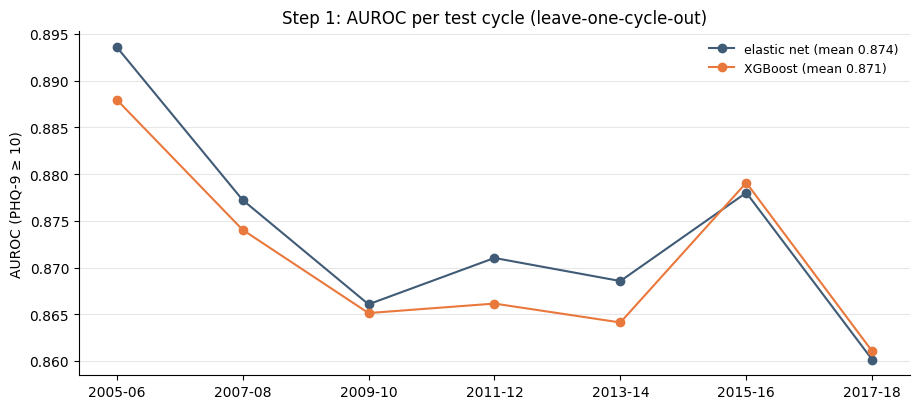

In [4]:
met = pd.read_csv(OUT / "metrics.csv")
plots.per_split_auroc(met, title="Step 1: AUROC per test cycle (leave-one-cycle-out)",
                      labels={"logreg": "elastic net", "xgboost": "XGBoost"})
plots.show()